# Лабораторная работа № 2
## Кластеризация методом k-средних. Леденцы

Разделим респондентов на группы по причинам употребления леденцов. Нужно выбрать число кластеров, описать их профили и понять, насколько результат зависит от начальных центров и масштаба признаков.

Используем тот же набор данных, что в первой работе. Разбиения для k-means рассчитываем заново. По заданию нужны понятные, измеримые и достаточно большие потребительские сегменты.

In [1]:
from pathlib import Path
from importlib.metadata import version
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, cut_tree
from matplotlib.patches import Rectangle

sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 15)

print("Python:", platform.python_version())
print("; ".join(f"{name}: {version(name)}" for name in
                ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn"]))

Python: 3.14.6
numpy: 2.4.6; pandas: 3.0.3; scipy: 1.18.0; scikit-learn: 1.9.0; matplotlib: 3.11.0; seaborn: 0.13.2


### 1. Данные

Одна строка - ответы одного респондента. Признаки V1–V11 показывают, насколько он согласен с разными причинами употребления леденцов:

| Признак | Причина |
|---|---|
| V1 | Освежить дыхание |
| V2 | Чувствовать себя увереннее |
| V3 | Освежить полость рта |
| V4 | Избавиться от неприятного вкуса |
| V5 | Заменить другие кондитерские изделия |
| V6 | Съесть что-нибудь сладкое |
| V7 | Сконцентрироваться |
| V8 | Отвлечься и подумать |
| V9 | Облегчить боль в горле |
| V10 | Избавиться от заложенности носа |
| V11 | Улучшить самочувствие |

Сначала загрузим таблицу и проверим, есть ли пропуски и повторяющиеся ответы.

In [2]:
def load_data(path, sep=";"):
    """Прочитать текстовую таблицу по пути path; sep задаёт разделитель."""
    return pd.read_csv(path, sep=sep)


data_path = Path("Леденцы.dat")
data = load_data(data_path)

display(data.head())
print("Размер таблицы:", data.shape)
print("Типы столбцов:", data.dtypes.astype(str).value_counts().to_dict())
print("Пропуски:", data.isna().sum().sum())
print("Повторные строки:", data.duplicated().sum())
print("Разные профили ответов:", len(data.drop_duplicates()))
print("Наблюдаемые оценки:", np.unique(data))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Размер таблицы: (338, 11)
Типы столбцов: {'int64': 11}
Пропуски: 0
Повторные строки: 293
Разные профили ответов: 45
Наблюдаемые оценки: [2 3 4 5]


В таблице **338 респондентов и 11 числовых признаков**, пропусков нет. Оценки принимают значения от 2 до 5. Словесные значения отдельных баллов в условии не заданы, поэтому, например, ответ 3 нельзя автоматически называть нейтральным.

Повторяются 293 строки; разных наборов ответов всего 45. Сохраняем всех людей: одинаковые ответы могут принадлежать разным респондентам. Если удалить повторы, распространённые профили потеряют свой вес и размеры сегментов изменятся.

Все вопросы имеют общую шкалу, поэтому основной анализ проведём на исходных оценках. Мы допускаем, что разница в один балл одинакова на разных участках шкалы. Для порядковых ответов это приближение. В конце отдельно проверим стандартизацию.

На первой карте покажем число ответов каждого значения. На второй — корреляции Спирмена: они помогают увидеть, какие вопросы меняются согласованно.

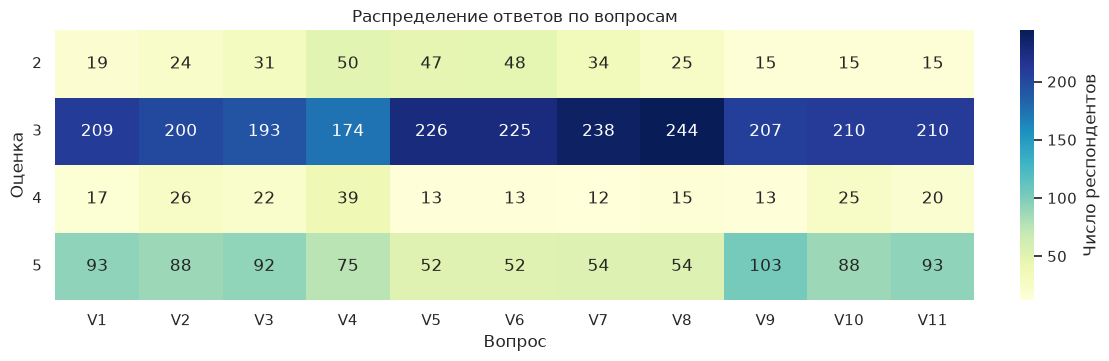

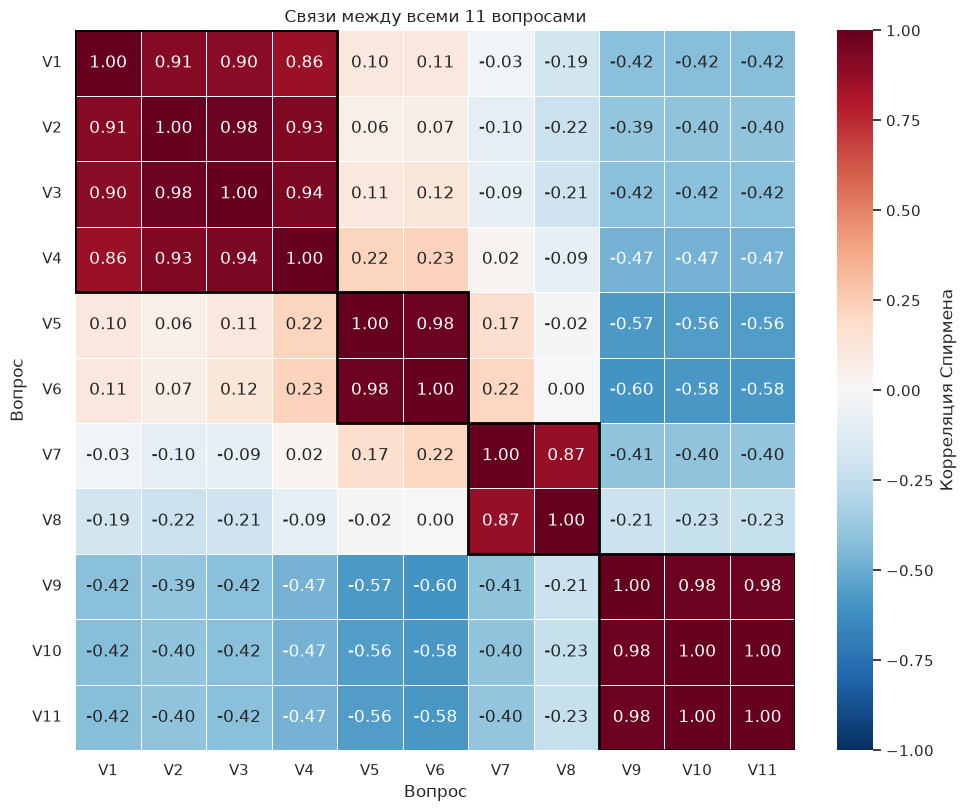

In [3]:
answer_counts = pd.DataFrame({column: data[column].value_counts()
                              for column in data.columns}).fillna(0).astype(int).sort_index()
fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
sns.heatmap(answer_counts, annot=True, fmt="d", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "Число респондентов"})
ax.set(title="Распределение ответов по вопросам", xlabel="Вопрос", ylabel="Оценка")
ax.tick_params(axis="both", rotation=0)
plt.show()

themes = {
    "Свежесть и уверенность": ["V1", "V2", "V3", "V4"],
    "Сладкое": ["V5", "V6"],
    "Концентрация и пауза": ["V7", "V8"],
    "Самочувствие": ["V9", "V10", "V11"],
}
spearman = data.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, linewidths=0.4, ax=ax,
            cbar_kws={"label": "Корреляция Спирмена"})
for columns in themes.values():
    start = data.columns.get_loc(columns[0])
    ax.add_patch(Rectangle((start, start), len(columns), len(columns),
                           fill=False, edgecolor="black", linewidth=2))
ax.set(title="Связи между всеми 11 вопросами", xlabel="Вопрос", ylabel="Вопрос")
ax.tick_params(axis="both", rotation=0)
plt.show()

Темы в чёрных рамках предложены по формулировкам: V1–V4 относятся к свежести и уверенности, V5–V6 — к сладкому, V7–V8 — к концентрации и паузе, V9–V11 — к самочувствию. Внутри этих тем корреляции действительно высокие: примерно 0,86–1,00.

Это позволяет обсуждать вопросы рядом, но не делает их взаимозаменяемыми. Например, «сконцентрироваться» и «отвлечься и подумать» — разные мотивы. Поэтому **не усредняем разные вопросы в один показатель**: k-means использует все 11 признаков отдельно. Количество тем не задаёт число кластеров.

### 2. Как работает k-means

Алгоритм ищет группы, внутри которых ответы близки к общему среднему профилю. Этот профиль называется **центром кластера**. Он содержит 11 средних оценок и не обязан совпадать с ответами конкретного человека.

Для заданного числа групп k алгоритм:

1. Выбирает начальные центры.
2. Относит каждого человека к ближайшему центру по евклидову расстоянию.
3. Пересчитывает центры как средние ответы людей своих групп.
4. Повторяет назначение и пересчёт до сходимости или достижения лимита итераций.

Критерий k-means — **inertia**, сумма квадратов расстояний людей до центров своих групп. Алгоритм старается уменьшить её, но может остановиться в локальном минимуме. Поэтому выполняем несколько запусков с разными начальными центрами и сохраняем вариант с наименьшей inertia.

В отличие от первой работы, здесь нет дерева слияний и дендрограммы. При каждом новом k группы рассчитываются заново; люди могут переходить между ними. Вложенность разбиений не гарантируется.

Настройки основного расчёта:

| Параметр | Значение и смысл |
|---|---|
| `init="k-means++"` | Выбор разнесённых начальных центров; уменьшает риск неудачного старта |
| `n_init=100` | Сто запусков для каждого k; выбирается наименьшая inertia |
| `random_state=42` | Фиксирует случайный выбор для повторения расчёта; само число 42 преимуществ не имеет |
| `max_iter=300` | Максимум шагов в одном запуске |
| `tol=1e-4` | Допуск для остановки по малому изменению центров |
| `algorithm="lloyd"` | Обычная схема назначения людей и пересчёта средних |

Сто запусков доступны по времени для этой небольшой таблицы. Они снижают зависимость от старта, но не гарантируют глобальный минимум. Это проверим отдельной серией начальных состояний. Параметр произвольной метрики не вводим: обычный k-means использует квадраты евклидовых расстояний.

In [4]:
def fit_kmeans(frame, n_clusters, n_init=100, random_state=42, max_iter=300):
    """Обучить k-means на frame и вернуть модель с центрами, метками и inertia.

    n_clusters задаёт число групп, n_init — число стартов, random_state —
    воспроизводимость, max_iter — лимит шагов одного старта.
    """
    model = KMeans(n_clusters=n_clusters, init="k-means++", n_init=n_init,
                   random_state=random_state, max_iter=max_iter,
                   tol=1e-4, algorithm="lloyd")
    return model.fit(frame)


def compare_k(frame, k_values, n_init=100, random_state=42, max_iter=300):
    """Вернуть таблицу критериев и словарь обученных моделей для всех k_values."""
    rows, models = [], {}
    for k in k_values:
        model = fit_kmeans(frame, k, n_init, random_state, max_iter)
        models[k] = model
        sizes = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
        rows.append({
            "k": k,
            "inertia": model.inertia_,
            "Силуэт": silhouette_score(frame, model.labels_) if k > 1 else np.nan,
            "Минимальный размер": sizes.min(),
            "Размеры групп": "/".join(sizes.astype(str)),
        })
    return pd.DataFrame(rows).set_index("k"), models


k_values = range(1, 11)
model_settings = {"n_init": 100, "random_state": 42, "max_iter": 300}
results, models = compare_k(data, k_values, **model_settings)
labels_by_k = {k: model.labels_ + 1 for k, model in models.items()}

`frame` — таблица признаков, `k_values` — проверяемые числа групп. Функция `fit_kmeans` возвращает модель; в `labels_` находятся метки людей, в `cluster_centers_` — центры, в `inertia_` — значение критерия. `compare_k` сохраняет модели, чтобы следующие графики использовали именно уже оценённые разбиения. Для подписей добавляем к меткам 1: нумерация начинается с единицы и не меняет состав групп.

### 3. Сравнение числа кластеров

Проверим k от 2 до 10. Дополнительно рассчитаем k=1 как начальную точку графика inertia. При увеличении числа центров минимально достижимая inertia не возрастает, поэтому просто выбирать её наименьшее значение нельзя: это подталкивало бы к всё большему k. **Метод локтя** ищет участок, после которого добавление кластеров даёт существенно меньший выигрыш. Это визуальный ориентир, а не строгий тест.

**Силуэт** сравнивает среднее расстояние человека до остальных людей своей группы `a` и наименьшее среднее расстояние до другой группы `b`: `s = (b - a) / max(a, b)`. В таблице используется среднее по всем 338 людям. Ближе к 1 — группы хорошо разделены; около 0 — близки; отрицательные значения указывают на возможное спорное отнесение. Для одной группы силуэт не определён. Значение 0,73 не означает точность 73%.

Сопоставим оба графика с размерами и содержанием групп. Силуэт рассчитывается по обычным евклидовым расстояниям, а inertia — по квадратам расстояний до центров. Это разные критерии, и k-means оптимизирует только второй.

,inertia,Силуэт,Минимальный размер,Размеры групп
k,,,,
1,3160.04,—,338,338
2,1823.30,0.4551,108,230/108
3,879.72,0.6140,108,120/110/108
4,423.14,0.7265,59,110/108/61/59
5,326.25,0.7024,42,110/66/61/59/42
6,286.59,0.7239,16,110/63/61/59/29/16
7,250.53,0.7257,15,110/63/59/46/29/16/15
8,222.21,0.6343,15,71/63/59/46/39/29/16/15
9,196.02,0.6578,4,92/59/59/46/29/18/16/15/4


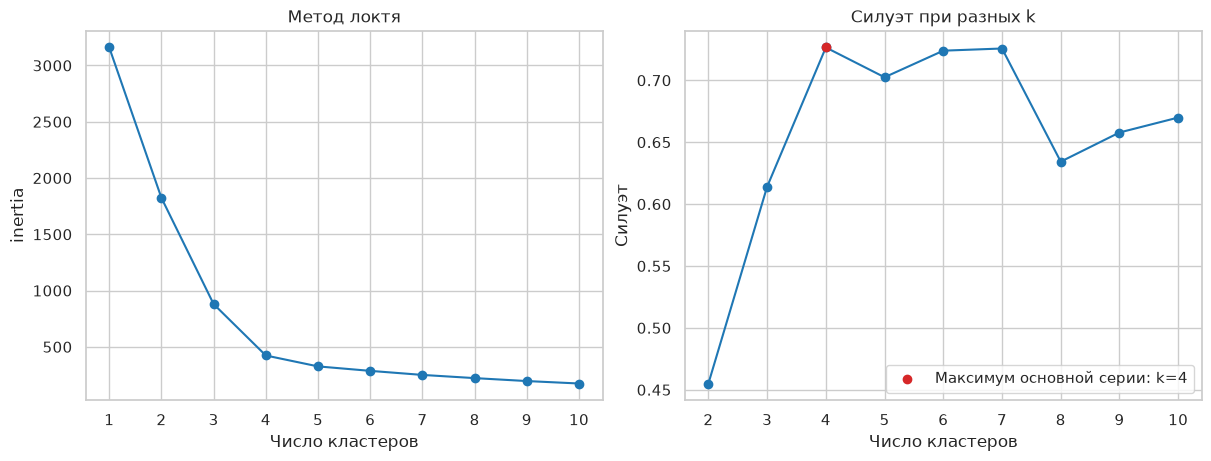

In [5]:
display(results.style.format({"inertia": "{:.2f}", "Силуэт": "{:.4f}"}, na_rep="—"))
best_k = int(results["Силуэт"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].plot(results.index, results["inertia"], "o-", color="#1f77b4")
axes[0].set(title="Метод локтя", xlabel="Число кластеров", ylabel="inertia",
            xticks=list(k_values))
axes[1].plot(results.index, results["Силуэт"], "o-", color="#1f77b4")
axes[1].scatter(best_k, results.loc[best_k, "Силуэт"], color="#d62728", zorder=3,
                label=f"Максимум основной серии: k={best_k}")
axes[1].set(title="Силуэт при разных k", xlabel="Число кластеров", ylabel="Силуэт",
            xticks=list(range(2, 11)))
axes[1].legend()
plt.show()

В основной серии лучший силуэт получился при **k=4: 0,7265**. При k=6 он равен 0,7239, а при k=7 — 0,7257: разница с четырьмя группами очень мала. При k=8 показатель снижается примерно до 0,6343. Это результаты указанных настроек, а не доказательство превосходства над всеми возможными запусками.

На графике inertia заметно замедление снижения после четырёх групп: при переходе 3→4 значение меняется с 879,72 до 423,14, а при 4→5 — только до 326,25. Поэтому четыре — разумный кандидат по локтю. Теперь проверим, действительно ли такое разбиение разделяет разные потребности и что дают шесть, семь и восемь групп.

### 4. Что меняется при разном числе групп

Сначала посмотрим на k=2, 3 и 4. На картах каждая строка — кластер, в скобках указана его численность. Каждая клетка — **среднее одного вопроса по людям этой группы**. Например, 3,90 получается сложением всех ответов V5 в группе и делением на её размер. Это не среднее по смысловой теме и не ответ каждого человека.

Все карты используют одну цветовую шкалу от 2 до 5. Номера кластеров условны: группа 1 при разных k может содержать разных людей.

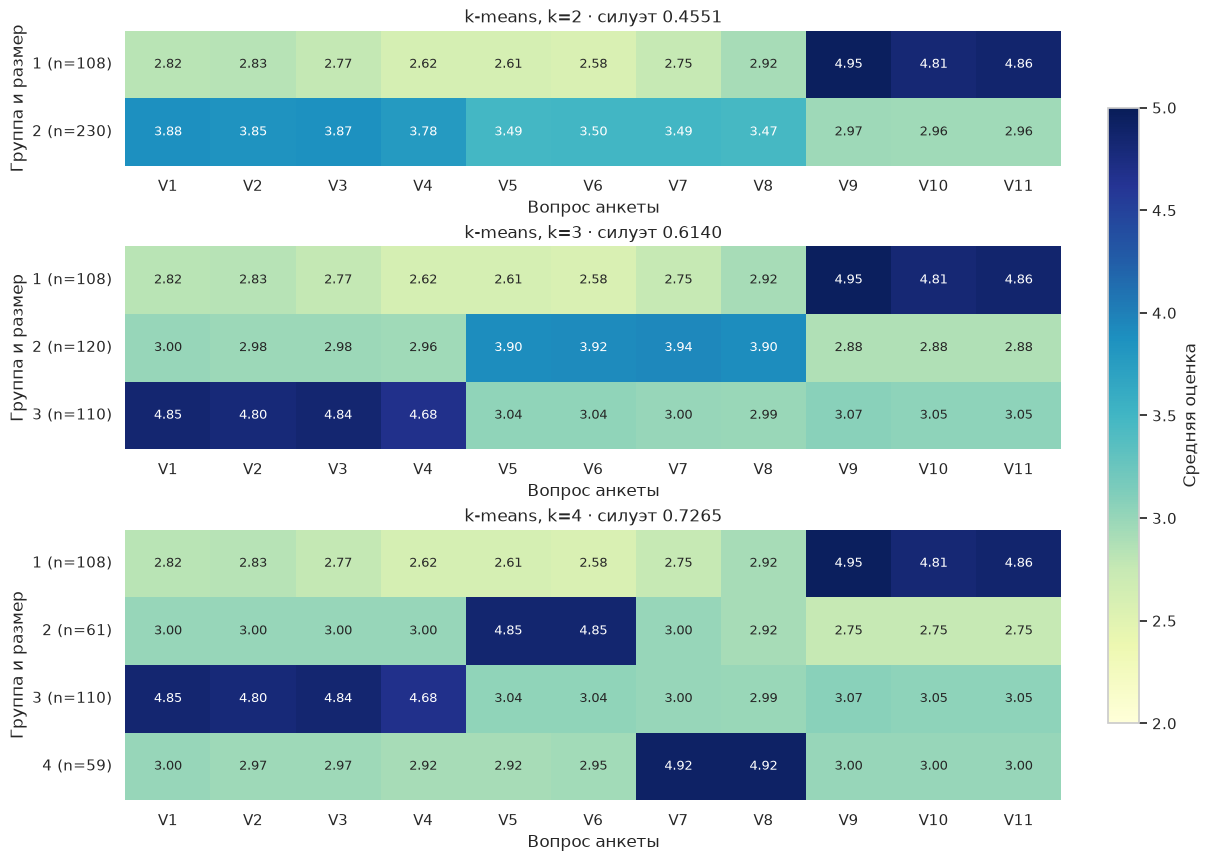

Переход k=2 → k=3:
  группа 1 (108 чел.) → 108 чел. в группу 1
  группа 2 (230 чел.) → 120 чел. в группу 2, 110 чел. в группу 3
Переход k=3 → k=4:
  группа 1 (108 чел.) → 108 чел. в группу 1
  группа 2 (120 чел.) → 61 чел. в группу 2, 59 чел. в группу 4
  группа 3 (110 чел.) → 110 чел. в группу 3


In [6]:
def plot_profile(frame, labels, ax, title, statistic="mean"):
    """Показать средние или медианы каждого вопроса по группам; вернуть цветовую карту."""
    groups = frame.assign(cluster=labels).groupby("cluster")
    profile = groups.mean() if statistic == "mean" else groups.median()
    row_labels = [f"{group} (n={size})" for group, size in groups.size().items()]
    sns.heatmap(profile, annot=True, fmt=".2f", cmap="YlGnBu", vmin=2, vmax=5,
                yticklabels=row_labels, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set(title=title, xlabel="Вопрос анкеты", ylabel="Группа и размер")
    ax.tick_params(axis="both", rotation=0)
    return ax.collections[0]


fig, axes = plt.subplots(3, 1, figsize=(12, 8.5),
                         gridspec_kw={"height_ratios": [2, 3, 4]}, constrained_layout=True)
for k, ax in zip([2, 3, 4], axes):
    color_source = plot_profile(data, labels_by_k[k], ax,
                                f"k-means, k={k} · силуэт {results.loc[k, 'Силуэт']:.4f}")
fig.colorbar(color_source, ax=axes.tolist(), shrink=0.8, label="Средняя оценка")
plt.show()

for before, after in [(2, 3), (3, 4)]:
    overlap = pd.crosstab(labels_by_k[before], labels_by_k[after])
    print(f"Переход k={before} → k={after}:")
    for group, row in overlap.iterrows():
        parts = ", ".join(f"{size} чел. в группу {child}" for child, size in row[row > 0].items())
        print(f"  группа {group} ({row.sum()} чел.) → {parts}")

При **двух группах** отдельно стоят 108 человек с высокими V9–V11, то есть мотивами самочувствия. Остальные 230 человек объединены, хотя их причины употребления различаются.

При **трёх группах** выделяются 110 человек с высокими V1–V4. В группе из 120 человек ещё смешаны сладкое и концентрация: например, средние V5=3,90 и V7≈3,94. При **четырёх** эти 120 делятся на 61 человека с высокими V5–V6 и 59 с высокими V7–V8. Результаты пересечений, напечатанные под картами, показывают, откуда взялись эти численности. Теперь разные ведущие мотивы можно описать отдельно.

**Более подробные варианты.** Рассмотрим k=6 и 7, которые близки к четырём по силуэту, и k=8, где показатель снижается. Покажем полные профили, чтобы увидеть изменения по отдельным вопросам.

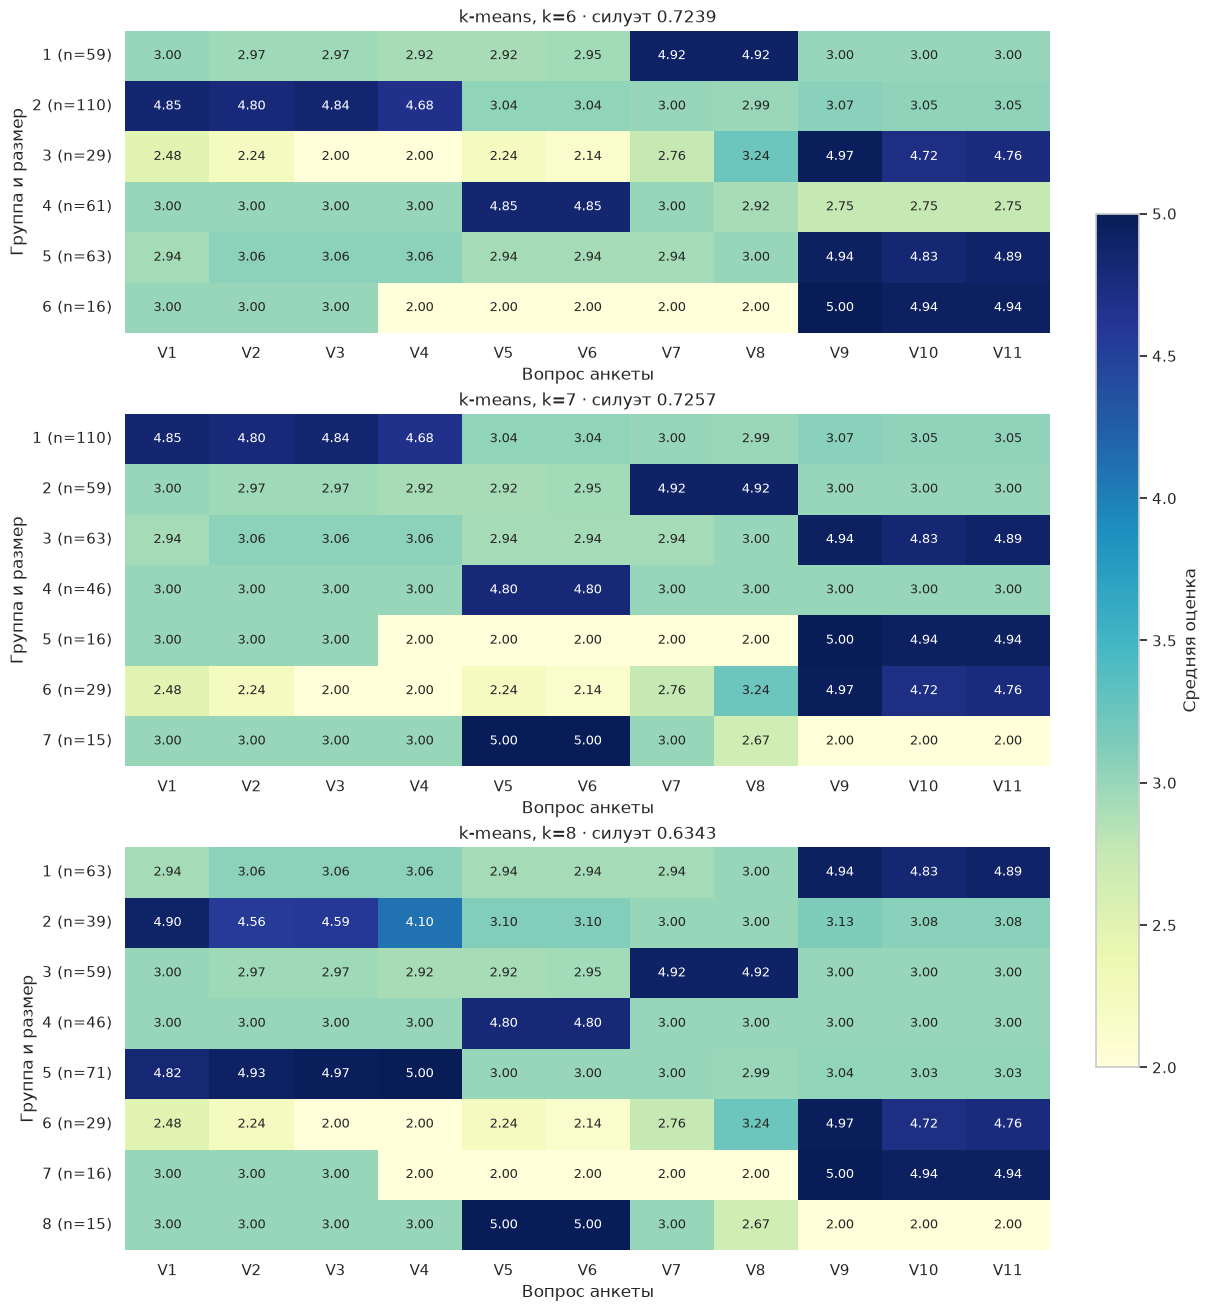

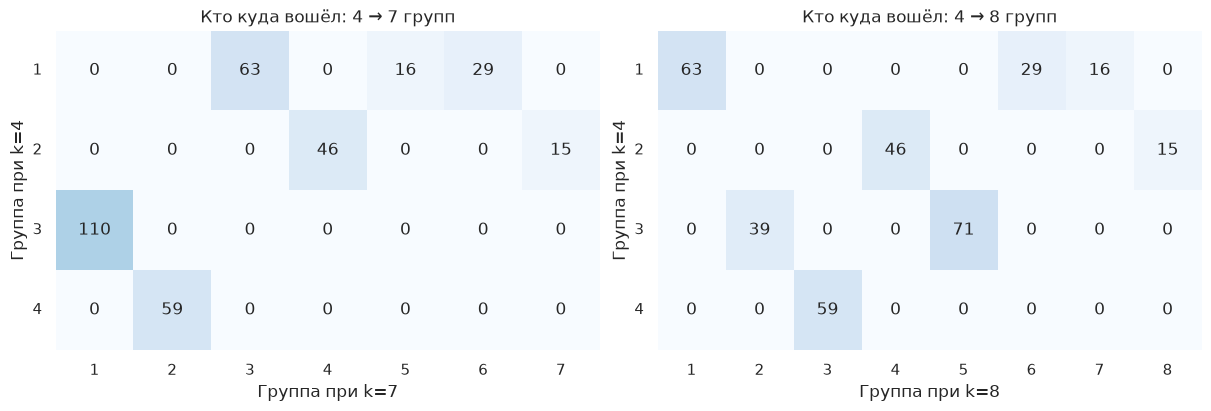

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 13),
                         gridspec_kw={"height_ratios": [6, 7, 8]}, constrained_layout=True)
for k, ax in zip([6, 7, 8], axes):
    color_source = plot_profile(data, labels_by_k[k], ax,
                                f"k-means, k={k} · силуэт {results.loc[k, 'Силуэт']:.4f}")
fig.colorbar(color_source, ax=axes.tolist(), shrink=0.7, label="Средняя оценка")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for k, ax in zip([7, 8], axes):
    overlap = pd.crosstab(labels_by_k[4], labels_by_k[k])
    sns.heatmap(overlap, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                vmin=0, vmax=len(data))
    ax.set(title=f"Кто куда вошёл: 4 → {k} групп", xlabel=f"Группа при k={k}",
           ylabel="Группа при k=4")
    ax.tick_params(axis="both", rotation=0)
plt.show()

**При шести группах** самочувствие делится на 29, 63 и 16 человек. V9–V11 во всех трёх высоки, различаются другие мотивы. Например, у 63 человек V1–V8 близки к 3; у 16 человек V4–V8 равны 2; у 29 человек V3=V4=2, но V7≈2,76 и V8≈3,24. Это подтипы одного крупного сегмента, а не три новых ведущих мотива.

**При семи группах** добавляется разделение сладкого на 46 и 15 человек. У первой подгруппы V5=V6≈4,80 и V9–V11=3, у второй V5=V6=5 и V9–V11=2. Такое уточнение имеет смысл, если нужно изучать сочетания мотивов. Силуэт почти равен варианту из четырёх групп, но описывать приходится уже семь сегментов, в том числе два небольших — 15 и 16 человек.

**При восьми группах** дополнительно разделяется свежесть: 110 → 39 + 71. У 39 человек V4≈4,10, а у 71 — 5; различаются также V2 и V3. При этом обе подгруппы по-прежнему высоко оценивают свежесть. Более низкая inertia показывает большую близость к своим центрам, но силуэт падает: новые группы хуже отделены от соседних.

На картах пересечений видно, что в этих конкретных расчётах мелкие группы целиком входят в крупные. Мы установили это по меткам людей; сам k-means такого свойства не гарантирует. Варианты 6–8 полезны для детализации, но пока четыре группы выглядят достаточными для общего описания основных потребностей.

### 5. Проверка решения и итоговые сегменты

Прежде чем зафиксировать выбор, проверим зависимость от инициализации. Для k=4 сравним один старт и 100 стартов при `random_state` от 0 до 9. Также повторим расчёты для близких альтернатив k=6, 7 и 8 со 100 стартами.

**ARI** сравнивает состав двух разбиений одних и тех же людей, учитывая случайное совпадение. ARI=1 означает полное совпадение состава; номера групп при этом могут различаться. Здесь сравниваем каждый результат с моделью того же k из основной серии. Это проверка начальных центров на тех же данных, а не проверка на новой выборке.

In [8]:
stability_rows = []
for k, restarts in [(4, 1), (4, model_settings["n_init"]),
                     (6, model_settings["n_init"]), (7, model_settings["n_init"]),
                     (8, model_settings["n_init"])]:
    for seed in range(10):
        candidate = fit_kmeans(data, k, n_init=restarts, random_state=seed,
                               max_iter=model_settings["max_iter"])
        stability_rows.append({
            "k": k, "n_init": restarts, "seed": seed,
            "ARI": adjusted_rand_score(models[k].labels_, candidate.labels_),
            "inertia": candidate.inertia_,
            "Силуэт": silhouette_score(data, candidate.labels_),
        })
stability = pd.DataFrame(stability_rows)
stability_summary = stability.groupby(["k", "n_init"]).agg(
    ari_min=("ARI", "min"), inertia_min=("inertia", "min"), inertia_max=("inertia", "max"),
    silhouette_min=("Силуэт", "min"), silhouette_max=("Силуэт", "max"))
display(stability_summary.rename(columns={
    "ari_min": "Минимальный ARI", "inertia_min": "Минимальная inertia",
    "inertia_max": "Максимальная inertia", "silhouette_min": "Минимальный силуэт",
    "silhouette_max": "Максимальный силуэт",
}).style.format("{:.4f}"))

С одним стартом для k=4 встречается неудачное решение: inertia около 804,32 вместо 423,14 и силуэт около 0,5601 вместо 0,7265. С **100 стартами все десять проверок k=4 дали тот же состав**, что основная серия: ARI=1.

Для более подробных вариантов состав иногда меняется даже при 100 стартах. У k=6 в отдельных проверках силуэт достигает **0,7291**, немного превышая показатель четырёх групп. Поэтому нельзя утверждать, что четыре лучше любого возможного запуска. Начальные состояния не подбирались ради нужного вывода; основной `random_state=42` сохранён. Если главная цель — искать более мелкие подтипы, шесть и семь групп остаются разумными альтернативами.

**Итоговый выбор — k-means с четырьмя кластерами.** Его поддерживают локоть, высокий силуэт, устойчивый состав и четыре различимых ведущих мотива. Более подробные варианты уточняют эти сегменты; небольшой выигрыш отдельного запуска по силуэту не перевешивает цель описать крупные потребительские группы.

Назовём группы по высоким оценкам на уже показанной карте k=4. Эти названия не участвовали в обучении. Средние повторно выводить не будем: покажем размеры и доли, а затем медианы как дополнительную характеристику.

,Сегмент,Респондентов,"Доля, %"
Группа,,,
1,Самочувствие,108,31.95
2,Сладкое,61,18.05
3,Свежесть и уверенность,110,32.54
4,Концентрация и пауза,59,17.46


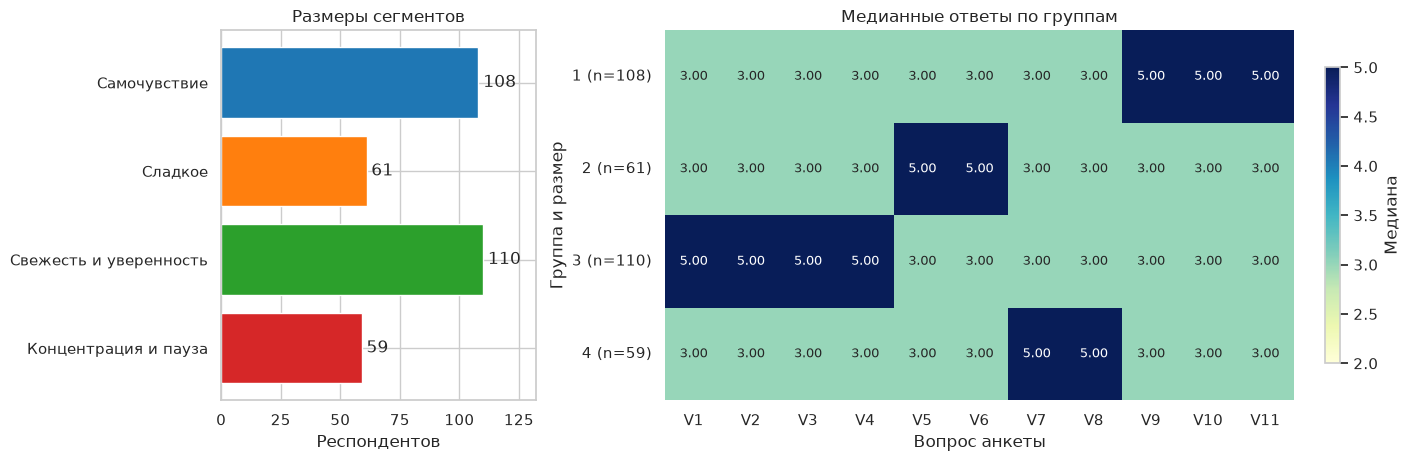

Распределены 338 из 338 респондентов; групп: 4.
Итераций в выбранном запуске: 2 из 300 допустимых.


In [9]:
n_clusters = 4
model = models[n_clusters]
labels = labels_by_k[n_clusters]
grouped = data.assign(cluster=labels).groupby("cluster")
means, medians, sizes = grouped.mean(), grouped.median(), grouped.size()
segment_names = {1: "Самочувствие", 2: "Сладкое",
                 3: "Свежесть и уверенность", 4: "Концентрация и пауза"}
summary = pd.DataFrame({"Сегмент": pd.Series(segment_names), "Респондентов": sizes,
                        "Доля, %": sizes / len(data) * 100})
summary.index.name = "Группа"
display(summary.style.format({"Доля, %": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5),
                         gridspec_kw={"width_ratios": [1, 2]}, constrained_layout=True)
colors = sns.color_palette("tab10", n_clusters)
axes[0].barh(summary["Сегмент"], sizes, color=colors)
for position, size in enumerate(sizes):
    axes[0].text(size + 2, position, str(size), va="center")
axes[0].invert_yaxis()
axes[0].set(title="Размеры сегментов", xlabel="Респондентов", xlim=(0, sizes.max() * 1.2))
color_source = plot_profile(data, labels, axes[1], "Медианные ответы по группам", statistic="median")
fig.colorbar(color_source, ax=axes[1], shrink=0.8, label="Медиана")
plt.show()

print(f"Распределены {sizes.sum()} из {len(data)} респондентов; групп: {len(sizes)}.")
print(f"Итераций в выбранном запуске: {model.n_iter_} из {model_settings['max_iter']} допустимых.")

**Самочувствие:** высокие V9–V11 описывают ожидания, связанные с горлом, носом и общим состоянием. **Сладкое:** высокие V5–V6 показывают желание сладкого и замену других кондитерских изделий. **Свежесть и уверенность:** высоки V1–V4. **Концентрация и пауза:** высоки V7–V8. Медианы ведущих вопросов равны 5, остальных — 3; это подтверждает основные различия, видимые по средним.

Для маркетинга такие группы могут стать отправной точкой для проверки разных сообщений о продукте: о свежести, вкусе, короткой паузе или ожидаемом комфорте. Однако ответы про самочувствие не доказывают лечебного действия. По этой анкете также нельзя узнать любимые марки, готовность платить или прибыльность сегмента.

Осталось проверить влияние масштаба признаков и сопоставить результат с первой работой. `StandardScaler` вычитает среднее каждого вопроса и делит на его стандартное отклонение. Повторим k-means в этой шкале. Для сравнения с Ward заново построим его разбиение на четыре группы по тем же данным, без зависимости от открытой первой тетради.

In [10]:
scaled_data = StandardScaler().fit_transform(data)
scaled_model = fit_kmeans(scaled_data, n_clusters, **model_settings)
ward_labels = cut_tree(linkage(data, method="ward", metric="euclidean"),
                       n_clusters=[n_clusters]).ravel()
print("ARI: исходные данные и стандартизованные:",
      adjusted_rand_score(model.labels_, scaled_model.labels_))
print("ARI: k-means и Ward при четырёх группах:",
      adjusted_rand_score(model.labels_, ward_labels))

ARI: исходные данные и стандартизованные: 1.0
ARI: k-means и Ward при четырёх группах: 1.0


Оба сравнения дают **ARI=1**: стандартизация не изменила состав четырёх групп, и он совпал с Ward из первой работы. Это дополнительная проверка, а не причина заранее выбирать четыре. Силуэты в исходной и стандартизованной шкалах напрямую не сравниваем: расстояния при таком преобразовании меняются.

### 6. Выводы и ограничения

Метод k-средних выделил четыре крупных сегмента: свежесть и уверенность, самочувствие, сладкое, концентрация и пауза. В разбиение вошли все 338 респондентов. Выбор опирается на критерии качества, профили групп и проверку разных начальных центров; шесть и семь групп можно использовать для более подробного изучения подтипов.

Результат относится к этой выборке. Шкала ответов порядковая, а расчёты предполагают равные интервалы. Коррелирующие вопросы усиливают вклад отдельных тем. K-means ориентирован на компактные группы вокруг средних, чувствителен к масштабу, выбросам и начальным центрам. Проверки на новой выборке нет, поэтому совпадение нескольких разбиений не доказывает существование единственно правильных сегментов.